# SupplyChainIQ — Global Supply Chain & Logistics Analytics

## Project Overview

SupplyChainIQ analyzes order, sales, profitability, delivery performance, and logistics patterns using the DataCo SMART Supply Chain dataset.

The project combines:

- PostgreSQL and SQL for data preparation and business analysis
- Python and Pandas for analytical exploration
- Statistical analysis for operational insights
- Machine learning for late-delivery prediction
- Automated tests for data and analytical pipeline validation

### Analytical Objectives

1. Evaluate delivery performance and late-delivery risk.
2. Compare shipping modes and their operational performance.
3. Analyze order, unit, sales, and profit trends over time.
4. Identify high-value product categories and their exposure to late deliveries.
5. Examine geographic differences in delivery performance.
6. Build a predictive model for late deliveries using information available at order time.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, URL
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

load_dotenv(PROJECT_ROOT / ".env")

db_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=os.getenv("DB_PORT"),
    database=os.getenv("DB_NAME"),
)

engine = create_engine(db_url)

print("Database connection established.")

Database connection established.


In [2]:
from src.statistics.demand_statistics import (
    summarize_monthly_demand,
    calculate_sales_order_correlation,
    calculate_profit_sales_correlation,
    monthly_sales_trend_test,
)

## 1. Dataset Overview

The analytical database contains order-item level records from the DataCo SMART Supply Chain dataset.

Personally identifiable customer fields such as email, password, street, and names are excluded from the analytical layer because they are not required for the business analysis.

In [3]:
overview = pd.read_sql(
    """
    SELECT
        COUNT(*) AS order_items,
        COUNT(DISTINCT order_id) AS orders,
        COUNT(DISTINCT customer_id) AS customers,
        SUM(order_item_quantity) AS units,
        ROUND(SUM(sales)::numeric, 2) AS total_sales,
        ROUND(SUM(order_profit_per_order)::numeric, 2) AS total_profit
    FROM stg_supply_chain_orders
    WHERE is_delivery_observation = 1;
    """,
    engine,
)

overview

,order_items,orders,customers,units,total_sales,total_profit
0,172765,62897,20261,367591,35214428.98,3806420.63


## 2. Delivery Performance

Delivery performance is evaluated using observable shipments only. Shipping-cancelled records are excluded from late-delivery performance calculations.

The primary operational metric is the percentage of order items classified as late deliveries.

In [4]:
delivery = pd.read_sql(
    """
    SELECT *
    FROM delivery_summary;
    """,
    engine,
)

delivery

,total_order_items,total_orders,total_customers,total_units,avg_actual_shipping_days,avg_scheduled_shipping_days,avg_shipping_delay_days,schedule_exceeded_rate_pct,late_delivery_rate_pct,total_sales,total_profit,avg_profit_per_order
0,172765,62897,20261,367591,3.5,2.93,0.57,57.29,57.29,35214428.98,3806420.63,22.03


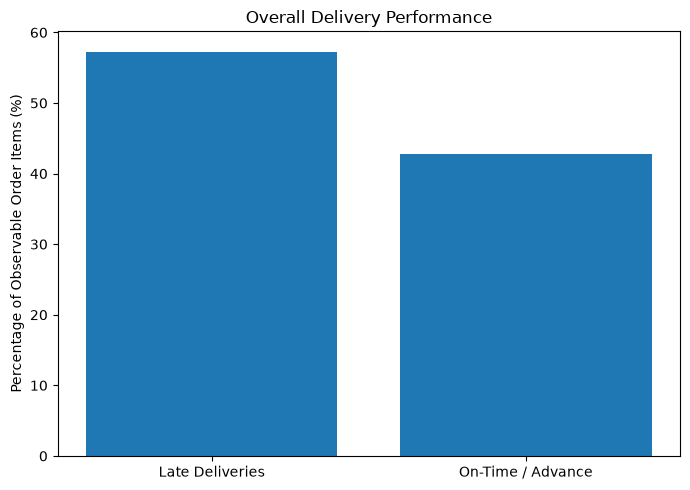

In [5]:
delivery_rate = delivery.loc[0, "late_delivery_rate_pct"]

plt.figure(figsize=(7, 5))

plt.bar(
    ["Late Deliveries", "On-Time / Advance"],
    [
        delivery_rate,
        100 - delivery_rate
    ]
)

plt.title("Overall Delivery Performance")
plt.ylabel("Percentage of Observable Order Items (%)")

plt.tight_layout()
plt.show()

### Key Observation

Approximately 57% of observable order items are classified as late deliveries.

This indicates that delivery reliability is a significant operational issue in the dataset and motivates further analysis of shipping modes, geography, product categories, and predictive risk factors.

## 3. Shipping Mode Analysis

Shipping modes are compared using:

- Actual shipping time
- Scheduled shipping time
- Average delay
- Late-delivery rate
- Sales
- Profit

A higher late-delivery rate does not necessarily mean that a shipping mode is operationally inferior because expedited modes have shorter promised delivery windows.

In [6]:
shipping_mode = pd.read_sql(
    """
    SELECT *
    FROM shipping_mode_analysis
    ORDER BY late_delivery_rate_pct DESC;
    """,
    engine,
)

shipping_mode

,shipping_mode,order_items,orders,avg_actual_shipping_days,avg_scheduled_shipping_days,avg_shipping_delay_days,late_delivery_rate_pct,schedule_exceeded_rate_pct,total_sales,total_profit
0,First Class,26513,9602,2.00,1.0,1.00,100.00,100.00,5408068.46,616596.73
1,Second Class,33806,12256,3.99,2.0,1.99,79.83,79.83,6860661.43,722861.47
2,Same Day,9293,3407,0.48,0.0,0.48,47.93,47.93,1854872.17,194182.13
3,Standard Class,103153,37632,3.99,4.0,-0.01,39.77,39.77,21090826.92,2272780.30


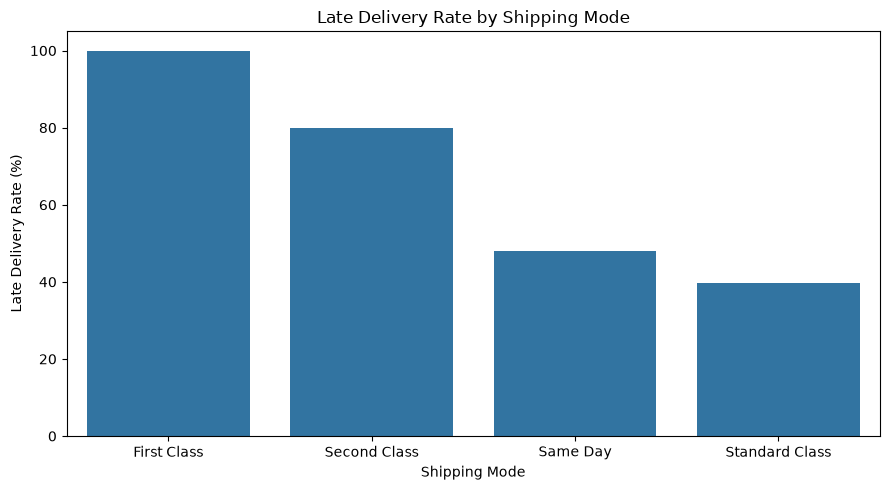

In [7]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=shipping_mode,
    x="shipping_mode",
    y="late_delivery_rate_pct"
)

plt.title("Late Delivery Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Delivery Rate (%)")

plt.tight_layout()
plt.show()

### Key Observation

Expedited shipping modes show substantially higher late-delivery rates than Standard Class.

This should not be interpreted as evidence that expedited logistics are inherently worse. These services operate with shorter promised delivery windows, meaning relatively small delays can trigger a late-delivery classification.

The result highlights the importance of evaluating delivery performance relative to the promised service level.

## 4. Demand and Sales Trends

Monthly order volume, units, sales, and profit are analyzed to identify demand trends and unusual structural changes.

In [8]:
monthly = pd.read_sql(
    """
    SELECT
        order_month_start,
        orders,
        units,
        total_sales,
        total_profit
    FROM monthly_demand_analysis
    ORDER BY order_month_start;
    """,
    engine,
)

monthly.head()

,order_month_start,orders,units,total_sales,total_profit
0,2015-01-01,1787,11854,1051590.06,111660.74
1,2015-02-01,1585,10438,927009.88,99140.66
2,2015-03-01,1781,12062,1051253.67,113778.21
3,2015-04-01,1710,11287,1014463.26,108083.68
4,2015-05-01,1776,11902,1050478.42,112147.90


In [9]:
monthly_statistics = summarize_monthly_demand(monthly)
monthly_statistics

,count,mean,std,min,25%,50%,75%,max
orders,37.0,1777.081081,123.908877,1585.00,1723.00,1763.00,1776.00,2124.00
units,37.0,10380.513514,2919.380848,2055.00,11033.00,11349.00,11676.00,12062.00
total_sales,37.0,994182.008378,161149.661441,331650.11,1014463.26,1037408.15,1049154.25,1143775.09
total_profit,37.0,107213.593784,17836.037787,33841.89,105002.69,111660.74,115111.07,131501.16


In [10]:
sales_order_correlation = calculate_sales_order_correlation(monthly)
profit_sales_correlation = calculate_profit_sales_correlation(monthly)

print(f"Orders vs Sales correlation: {sales_order_correlation:.4f}")
print(f"Sales vs Profit correlation: {profit_sales_correlation:.4f}")

Orders vs Sales correlation: -0.6808
Sales vs Profit correlation: 0.9288


In [11]:
trend_result = monthly_sales_trend_test(monthly)

print(f"Sales trend slope: {trend_result['slope']:.2f}")
print(f"R-squared: {trend_result['r_squared']:.4f}")
print(f"P-value: {trend_result['p_value']:.4f}")

Sales trend slope: -5186.62
R-squared: 0.1214
P-value: 0.0346


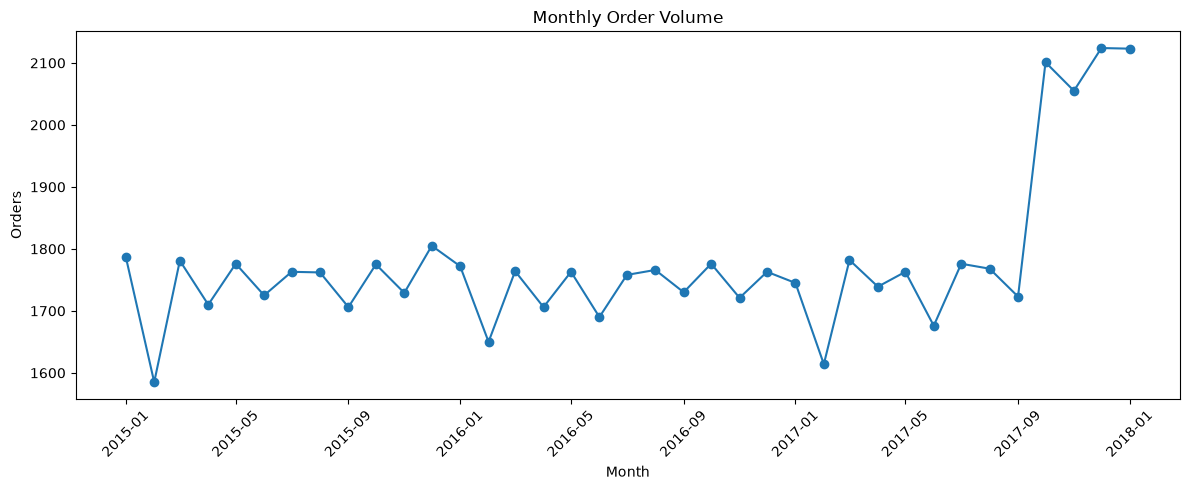

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly["order_month_start"],
    monthly["orders"],
    marker="o"
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

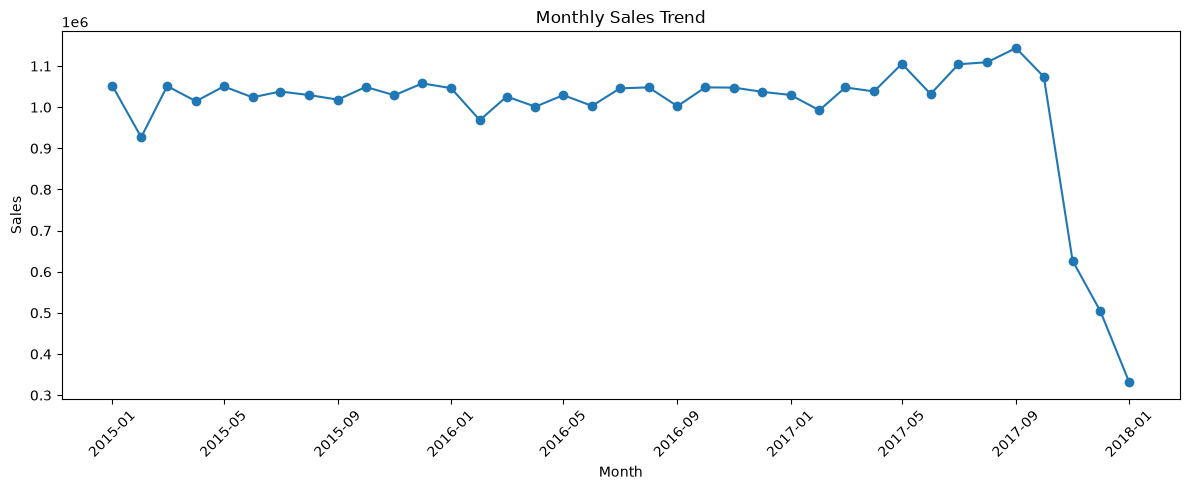

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly["order_month_start"],
    monthly["total_sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

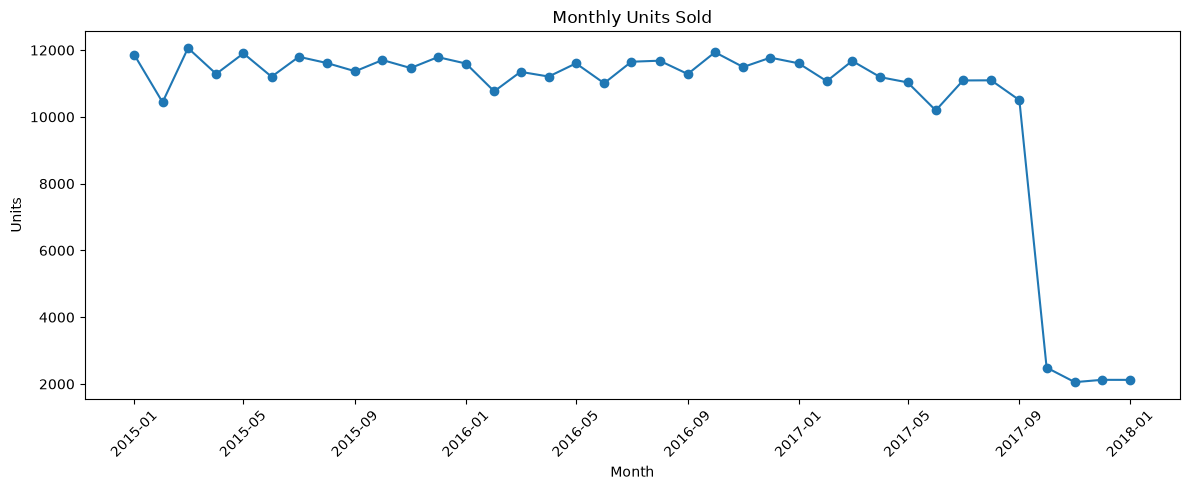

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly["order_month_start"],
    monthly["units"],
    marker="o"
)

plt.title("Monthly Units Sold")
plt.xlabel("Month")
plt.ylabel("Units")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Key Observation

Order volume and sales remain relatively stable across most of the observation period.

However, the final months of the dataset show a structural change in the relationship between orders and units. During late 2017 and early 2018, order counts remain relatively high while units per order decrease substantially.

These records should therefore be interpreted cautiously rather than being treated as evidence of a straightforward demand collapse.

## 5. Product and Category Analysis

Product categories are evaluated based on:

- Sales
- Profit
- Order volume
- Late-delivery rate
- Sales exposure to late deliveries

The exposure metric represents the portion of category sales associated with late-delivery observations. It should not be interpreted as sales actually lost because of late delivery.

In [15]:
category = pd.read_sql(
    """
    SELECT
        category_name,
        department_name,
        order_items,
        orders,
        customers,
        units,
        total_sales,
        total_profit,
        late_delivery_rate_pct,
        sales_exposure_to_late_delivery,
        profit_exposure_to_late_delivery
    FROM category_delivery_exposure
    ORDER BY total_sales DESC;
    """,
    engine,
)

category.head(15)

,category_name,department_name,order_items,orders,customers,units,total_sales,total_profit,late_delivery_rate_pct,sales_exposure_to_late_delivery,profit_exposure_to_late_delivery
0,Fishing,Fan Shop,16595,14527,8558,16595,6637668.10,731576.18,57.34,3806209.68,419504.61
1,Cleats,Apparel,23514,19534,9880,70611,4244593.89,474629.51,57.40,2436209.88,272416.43
2,Camping & Hiking,Fan Shop,13157,11787,7600,13157,3946836.86,409895.62,56.91,2245950.26,233251.39
3,Cardio Equipment,Footwear,11948,10857,7282,35937,3533289.21,362984.70,56.96,2012389.78,206738.44
4,Women's Apparel,Golf,20116,17088,9265,60232,3011600.00,334335.53,57.05,1718091.15,190735.46
5,Water Sports,Fan Shop,14880,13174,8098,14880,2981851.20,308981.34,57.24,1706749.10,176854.44
6,Indoor/Outdoor Games,Fan Shop,18470,15912,8955,55333,2765543.34,302403.77,57.20,1581914.75,172977.58
7,Men's Footwear,Apparel,21263,17954,9523,21263,2763977.37,296711.09,57.01,1575608.79,169140.53
8,Shop By Sport,Golf,10515,9700,6736,31329,1253395.61,125077.03,57.61,722117.98,72060.55
9,Computers,Technology,425,425,425,425,637500.00,69232.11,52.71,336000.00,36489.39


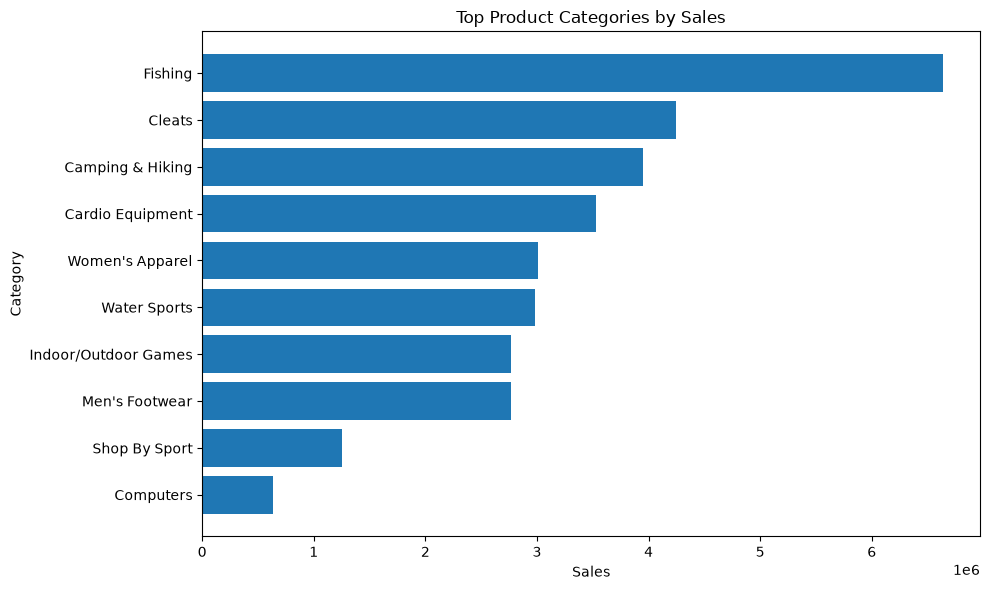

In [16]:
top_categories = (
    category
    .head(10)
    .sort_values("total_sales")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["category_name"],
    top_categories["total_sales"]
)

plt.title("Top Product Categories by Sales")
plt.xlabel("Sales")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

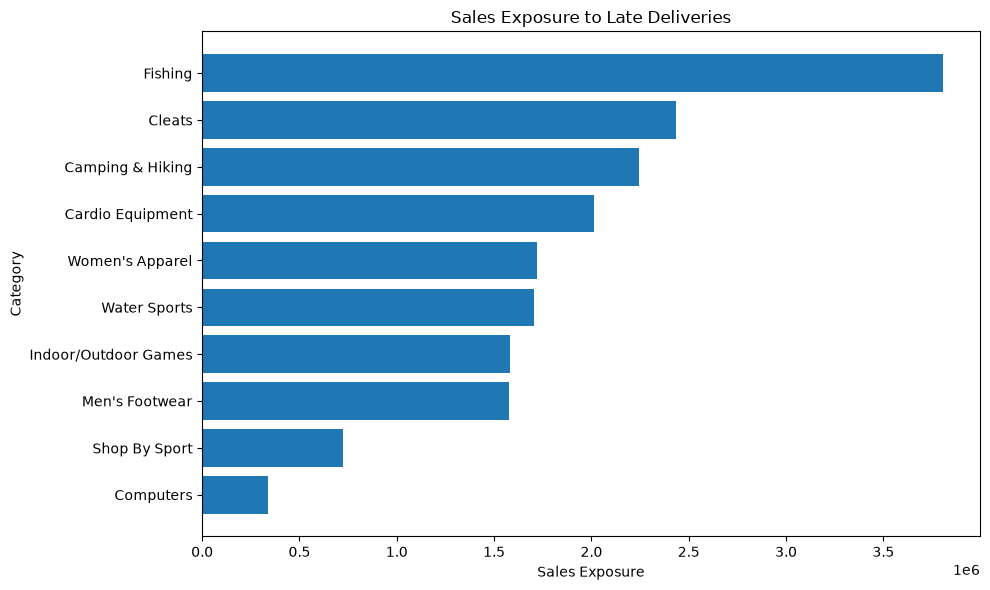

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["category_name"],
    top_categories["sales_exposure_to_late_delivery"]
)

plt.title("Sales Exposure to Late Deliveries")
plt.xlabel("Sales Exposure")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

### Key Observation

The major product categories have relatively similar late-delivery rates, generally close to the overall dataset level.

Therefore, category alone does not strongly differentiate delivery risk among the largest categories.

However, high-volume categories have greater commercial exposure because the same late-delivery rate applies to a larger sales base. These categories can therefore be useful priorities for operational improvement.

## 6. Geographic Delivery Analysis

Delivery performance is compared across markets and geographic regions to identify areas with relatively higher or lower late-delivery rates.

In [18]:
market = pd.read_sql(
    """
    SELECT
        market,
        COUNT(*) AS order_items,
        ROUND(AVG(is_late_delivery::numeric) * 100, 2)
            AS late_delivery_rate_pct,
        ROUND(SUM(sales)::numeric, 2) AS total_sales
    FROM stg_supply_chain_orders
    WHERE is_delivery_observation = 1
    GROUP BY market
    ORDER BY late_delivery_rate_pct DESC;
    """,
    engine,
)

market

,market,order_items,late_delivery_rate_pct,total_sales
0,Europe,48090,57.69,10405371.25
1,USCA,24627,57.41,4836413.48
2,Pacific Asia,39585,57.38,7942351.67
3,LATAM,49309,56.87,9824329.57
4,Africa,11154,56.84,2205963.01


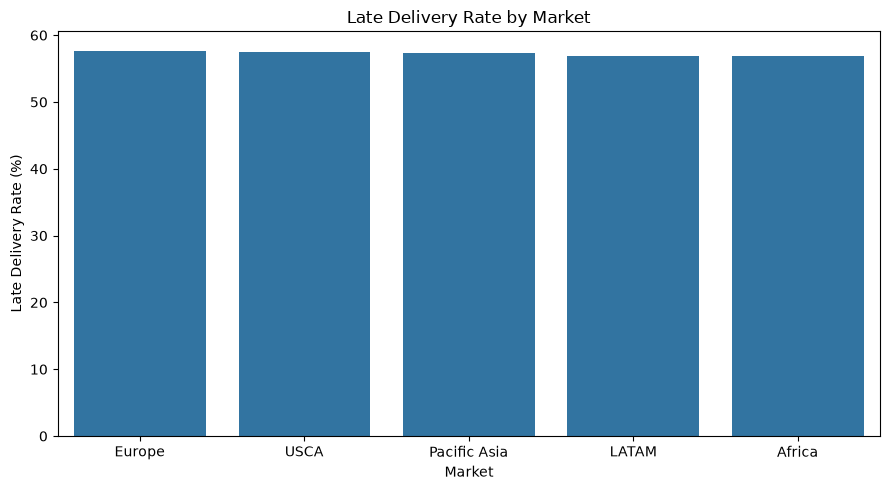

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=market,
    x="market",
    y="late_delivery_rate_pct"
)

plt.title("Late Delivery Rate by Market")
plt.xlabel("Market")
plt.ylabel("Late Delivery Rate (%)")

plt.tight_layout()
plt.show()

### Key Observation

Late-delivery rates are relatively close across the major markets. This suggests that broad market classification alone is not a strong differentiator of delivery risk.

More granular operational factors such as shipping mode, geographic region, and order characteristics are therefore more useful for investigating delivery performance.

## 7. Late Delivery Prediction

A machine-learning model is used to predict whether an observable order item will be delivered late.

Only information available at order time is used as predictive input.

Post-delivery variables such as actual shipping duration, shipping date, delivery status, and calculated delivery delay are excluded to prevent target leakage.

In [20]:
from src.modeling.late_delivery_model import (
    load_ml_dataset,
    time_based_split,
)

ml_data = load_ml_dataset(engine)

print("ML dataset shape:", ml_data.shape)
ml_data.head()

ML dataset shape: (172765, 22)


,order_item_id,order_id,order_date,target_late_delivery,shipping_mode,market,order_region,order_state,category_name,department_name,...,product_price,order_item_product_price,order_item_quantity,order_item_discount,order_item_discount_rate,order_year,order_month,order_day_of_week,order_day,is_weekend
0,1,1,2015-01-01 00:00:00,0,Standard Class,LATAM,Central America,Distrito Federal,Camping & Hiking,Fan Shop,...,299.98,299.98,1,60.0,0.20,2015,1,4,1,0
1,2,2,2015-01-01 00:21:00,0,Standard Class,LATAM,South America,Risaralda,Water Sports,Fan Shop,...,199.99,199.99,1,6.0,0.03,2015,1,4,1,0
2,3,2,2015-01-01 00:21:00,0,Standard Class,LATAM,South America,Risaralda,Women's Apparel,Golf,...,50.00,50.00,5,22.5,0.09,2015,1,4,1,0
3,4,2,2015-01-01 00:21:00,0,Standard Class,LATAM,South America,Risaralda,Men's Footwear,Apparel,...,129.99,129.99,1,22.1,0.17,2015,1,4,1,0
4,5,4,2015-01-01 01:03:00,1,Standard Class,LATAM,South America,Risaralda,Accessories,Outdoors,...,24.99,24.99,2,9.0,0.18,2015,1,4,1,0


In [21]:
train_df, test_df = time_based_split(ml_data)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print(
    "\nTrain period:",
    train_df["order_date"].min(),
    "to",
    train_df["order_date"].max()
)

print(
    "Test period:",
    test_df["order_date"].min(),
    "to",
    test_df["order_date"].max()
)

Train shape: (138211, 22)
Test shape: (34554, 22)

Train period: 2015-01-01 00:00:00 to 2017-04-22 03:22:00
Test period: 2017-04-22 03:43:00 to 2018-01-31 23:38:00


In [22]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "HistGradientBoosting"
    ],
    "ROC-AUC": [
        0.7448,
        0.7391
    ],
    "PR-AUC": [
        0.8351,
        0.8338
    ],
    "F1": [
        0.6769,
        0.6752
    ],
    "Precision": [
        0.8492,
        0.8474
    ],
    "Recall": [
        0.5627,
        0.5612
    ]
})

model_results

,Model,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,0.7448,0.8351,0.6769,0.8492,0.5627
1,HistGradientBoosting,0.7391,0.8338,0.6752,0.8474,0.5612


### Model Selection

Logistic Regression slightly outperforms HistGradientBoosting across the evaluated metrics.

The Logistic Regression model achieves:

- ROC-AUC: **0.7448**
- PR-AUC: **0.8351**
- F1: **0.6769**
- Precision: **0.8492**
- Recall: **0.5627**

Because the performance difference is small and Logistic Regression provides a simpler and more interpretable model, it is selected as the final model.

## 8. Prediction Threshold Analysis

The default classification threshold of 0.50 is not necessarily optimal for an operational intervention system.

Lowering the threshold increases recall, allowing more potentially late deliveries to be identified, at the cost of additional false positives.

In [23]:
threshold_results = pd.DataFrame({
    "Threshold": [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70],
    "Precision": [0.5932, 0.6206, 0.6926, 0.7886, 0.8492, 0.8685, 0.8780, 0.8824, 0.8884],
    "Recall": [0.9346, 0.8722, 0.7224, 0.6141, 0.5627, 0.5460, 0.5379, 0.5290, 0.5130],
    "F1": [0.7258, 0.7252, 0.7072, 0.6905, 0.6769, 0.6705, 0.6671, 0.6614, 0.6504],
})

threshold_results

,Threshold,Precision,Recall,F1
0,0.30,0.5932,0.9346,0.7258
1,0.35,0.6206,0.8722,0.7252
2,0.40,0.6926,0.7224,0.7072
3,0.45,0.7886,0.6141,0.6905
4,0.50,0.8492,0.5627,0.6769
5,0.55,0.8685,0.5460,0.6705
6,0.60,0.8780,0.5379,0.6671
7,0.65,0.8824,0.5290,0.6614
8,0.70,0.8884,0.5130,0.6504


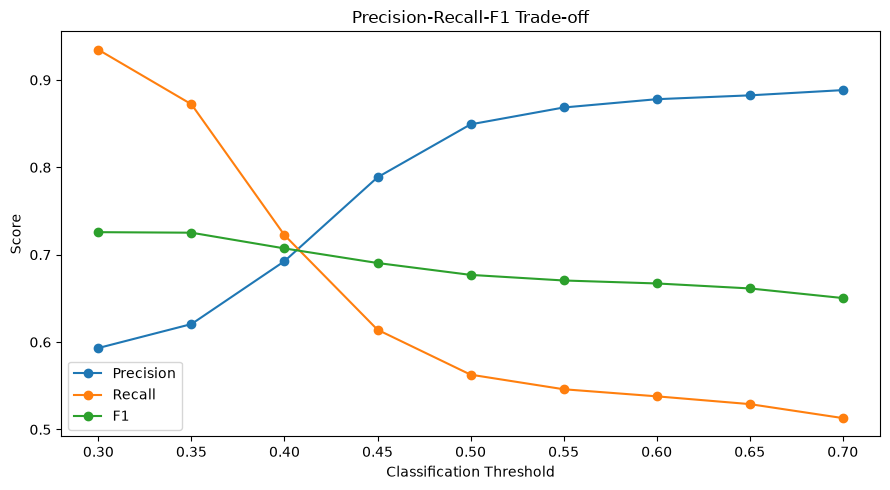

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall-F1 Trade-off")

plt.legend()
plt.tight_layout()
plt.show()

### Operational Interpretation

Among the tested thresholds, **0.30 produces the highest F1 score (0.7258)** and increases recall to **93.46%**, compared with **56.27%** at the default 0.50 threshold.

However, the appropriate operational threshold depends on the cost of intervention.

For example, if proactively contacting or rerouting potentially risky shipments is relatively inexpensive, a lower threshold may be preferable because it identifies more risky deliveries.

# 9. Business Insights & Conclusions

### 1. Delivery reliability is a major operational issue

Approximately 57% of observable order items are classified as late deliveries.

### 2. Expedited shipping requires closer monitoring

First Class and Second Class shipments have substantially higher late-delivery rates because their promised delivery windows are shorter.

### 3. Major product categories have similar delivery risk

The largest categories generally have late-delivery rates close to the overall average, suggesting that category alone is not a strong predictor of delivery performance.

### 4. High-volume categories have greater commercial exposure

Categories with large sales volumes represent greater financial exposure to late deliveries even when their late-delivery rates are similar to other categories.

### 5. Demand is relatively stable for most of the dataset

Monthly order volume and sales remain relatively stable over most of the observation period.

### 6. The final months require cautious interpretation

Late-2017 and early-2018 records show a structural change in the relationship between orders and units. These observations should be investigated before being used for straightforward demand forecasting.

### 7. Late-delivery prediction is feasible

The Logistic Regression model achieves a ROC-AUC of 0.7448 and PR-AUC of 0.8351 using order-time information.

### 8. Prediction thresholds should reflect business costs

A threshold of 0.30 substantially improves recall, making the model more suitable when the cost of missing a risky shipment is high. The threshold should ultimately be selected using the organization's intervention costs and capacity.

# Conclusion

SupplyChainIQ demonstrates an end-to-end supply-chain analytics workflow covering data validation, SQL transformation, descriptive analytics, operational analysis, and predictive modeling.

The analysis identifies delivery reliability as a major operational challenge, highlights the relationship between shipping service levels and late-delivery risk, identifies high-value categories with greater exposure, and demonstrates that machine learning can provide useful early warning signals for potentially late shipments.

The project emphasizes reproducibility through PostgreSQL-based transformations, Python analysis, chronological model validation, and automated tests.